# Case File 05: The Records Office
**Objective 5 · SQL querying**

**The case.** A digital music store wants to know where its money comes from: which countries, genres and customers matter,
and what isn't selling at all.

**The witness.** The [Chinook sample database](https://github.com/lerocha/chinook-database) (SQLite): customers, invoices,
invoice lines, tracks, albums, artists and genres, so it needs real joins.

All queries live in `sql/chinook_queries.sql`. This notebook reads that file, so the SQL is version-controlled in one place.

In [1]:
import re
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from pathlib import Path
FIG = Path("../reports/figures")
FIG.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 140)

con = sqlite3.connect("../data/raw/Chinook_Sqlite.sqlite")

def q(sql: str) -> pd.DataFrame:
    """Run SQL and return a DataFrame."""
    return pd.read_sql_query(sql, con)

# Load the five queries from the .sql file
text = Path("../sql/chinook_queries.sql").read_text()
queries = [s.strip() for s in text.split(";") if "SELECT" in s.upper()]
print(f"Loaded {len(queries)} queries")

Loaded 5 queries


## 1. Look at the schema first

In [2]:
tables = q("SELECT name FROM sqlite_master WHERE type = 'table' ORDER BY name")["name"].tolist()
for t in tables:
    n = q(f"SELECT COUNT(*) AS n FROM {t}")["n"][0]
    cols = ", ".join(q(f"PRAGMA table_info({t})")["name"])
    print(f"{t:12s} {n:>6,} rows  | {cols}")

Album           347 rows  | AlbumId, Title, ArtistId
Artist          275 rows  | ArtistId, Name
Customer         59 rows  | CustomerId, FirstName, LastName, Company, Address, City, State, Country, PostalCode, Phone, Fax, Email, SupportRepId
Employee          8 rows  | EmployeeId, LastName, FirstName, Title, ReportsTo, BirthDate, HireDate, Address, City, State, Country, PostalCode, Phone, Fax, Email
Genre            25 rows  | GenreId, Name
Invoice         412 rows  | InvoiceId, CustomerId, InvoiceDate, BillingAddress, BillingCity, BillingState, BillingCountry, BillingPostalCode, Total
InvoiceLine   2,240 rows  | InvoiceLineId, InvoiceId, TrackId, UnitPrice, Quantity
MediaType         5 rows  | MediaTypeId, Name
Playlist         18 rows  | PlaylistId, Name
PlaylistTrack  8,715 rows  | PlaylistId, TrackId
Track         3,503 rows  | TrackId, Name, AlbumId, MediaTypeId, GenreId, Composer, Milliseconds, Bytes, UnitPrice


## 2. Where does the money come from? (joins and aggregation)
*Business question: which countries bring in the most revenue, and how much per customer?*

In [3]:
q(queries[0])

,Country,customers,revenue,revenue_per_customer
0,USA,13,523.06,40.24
1,Canada,8,303.96,37.99
2,France,5,195.10,39.02
3,Brazil,5,190.10,38.02
4,Germany,4,156.48,39.12
5,United Kingdom,3,112.86,37.62
6,Czech Republic,2,90.24,45.12
7,Portugal,2,77.24,38.62
8,India,2,75.26,37.63
9,Chile,1,46.62,46.62


## 3. Which genres drive revenue? (window function over the whole result)

In [4]:
genre = q(queries[1])
genre.head(10)

,genre,revenue,pct_of_total
0,Rock,826.65,35.5
1,Latin,382.14,16.4
2,Metal,261.36,11.2
3,Alternative & Punk,241.56,10.4
4,TV Shows,93.53,4.0
5,Jazz,79.20,3.4
6,Blues,60.39,2.6
7,Drama,57.71,2.5
8,R&B/Soul,40.59,1.7
9,Classical,40.59,1.7


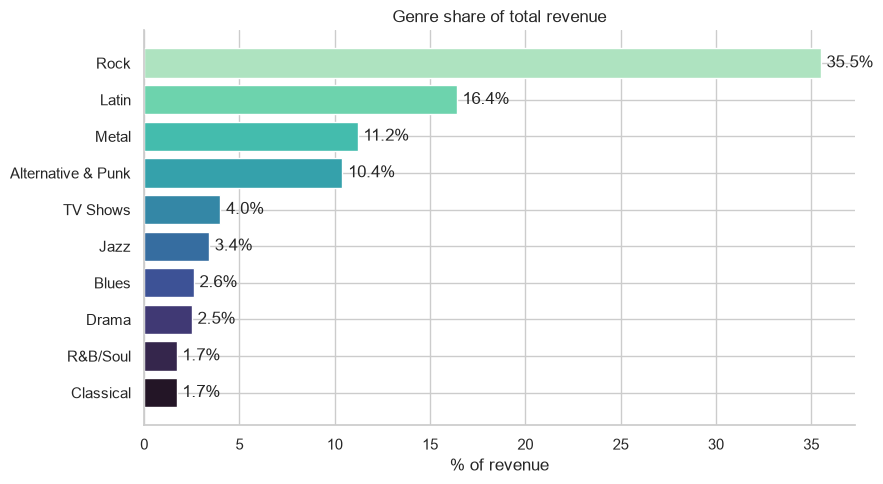

In [5]:
fig, ax = plt.subplots(figsize=(9, 5))
top = genre.head(10).iloc[::-1]
ax.barh(top["genre"], top["pct_of_total"], color=sns.color_palette("mako", 10))
for i, v in enumerate(top["pct_of_total"]):
    ax.text(v + 0.3, i, f"{v}%", va="center")
ax.set(title="Genre share of total revenue", xlabel="% of revenue", ylabel="")
sns.despine()
plt.tight_layout()
plt.savefig(FIG / "F_genre_revenue.png", dpi=200)
plt.show()

## 4. How is revenue trending? (CTE, `LAG`, running total)

In [6]:
monthly = q(queries[2])
monthly.head(12)

,month,revenue,mom_growth_pct,running_total
0,2021-01,35.64,NaN,35.64
1,2021-02,37.62,5.6,73.26
2,2021-03,37.62,0.0,110.88
3,2021-04,37.62,0.0,148.50
4,2021-05,37.62,0.0,186.12
5,2021-06,37.62,0.0,223.74
6,2021-07,37.62,0.0,261.36
7,2021-08,37.62,0.0,298.98
8,2021-09,37.62,0.0,336.60
9,2021-10,37.62,0.0,374.22


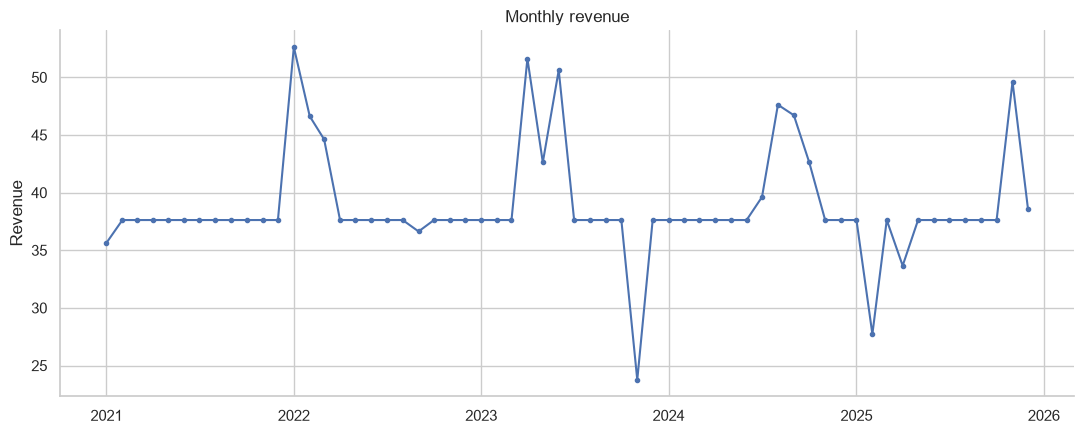

Months covered: 60 | average monthly revenue: 38.81


In [7]:
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(pd.to_datetime(monthly["month"]), monthly["revenue"], marker="o", ms=3)
ax.set(title="Monthly revenue", xlabel="", ylabel="Revenue")
sns.despine()
plt.tight_layout()
plt.savefig(FIG / "G_monthly_revenue.png", dpi=200)
plt.show()
print("Months covered:", len(monthly), "| average monthly revenue:", round(monthly["revenue"].mean(), 2))

## 5. Who is the best customer in each country? (`RANK` within a partition)

In [8]:
q(queries[3]).head(15)

,Country,customer,lifetime_value
0,Czech Republic,Helena Holý,49.62
1,USA,Richard Cunningham,47.62
2,Chile,Luis Rojas,46.62
3,Hungary,Ladislav Kovács,45.62
4,Ireland,Hugh O'Reilly,45.62
5,Germany,Fynn Zimmermann,43.62
6,Austria,Astrid Gruber,42.62
7,Finland,Terhi Hämäläinen,41.62
8,France,Isabelle Mercier,40.62
9,Netherlands,Johannes Van der Berg,40.62


## 6. What never sells? (anti-join)

In [9]:
q(queries[4])

,genre,unsold_tracks
0,Rock,552
1,Latin,239
2,Metal,143
3,Alternative & Punk,129
4,Jazz,62
5,TV Shows,50
6,Classical,38
7,Drama,37
8,Reggae,30
9,Blues,28


In [10]:
con.close()

## What the records show (numbers from the outputs above)

- **Where the money comes from:** the USA brings in the most revenue (about 523 across 13 customers), followed by Canada (about 304) and France (about 195). Revenue per customer is similar everywhere, roughly 37 to 47, so total revenue mostly tracks customer count rather than spending habits.
- **Genres:** Rock is the largest at 35.5% of revenue, then Latin (16.4%), Metal (11.2%) and Alternative & Punk (10.4%). Together these four genres make up nearly three-quarters of revenue (about 73.5%).
- **Trend:** monthly revenue is almost perfectly flat (about 37.6 in each of the first twelve months, averaging 38.8 over all 60 months), which is a sign this is a teaching sample rather than real trading data. I would not draw seasonal conclusions from it.
- **Unsold catalogue:** the genres with the most tracks that never sold are also the biggest sellers (Rock 552, Latin 239, Metal 143), simply because they have the largest catalogues. A fairer measure would be the *share* of each genre's tracks that never sold.

## Case closed when
every query has a one-line comment explaining the *business question* it answers, not just what the syntax does.
That's already true in `sql/chinook_queries.sql`.